# NB3 — Teaching the MNIST GAN Truncation Investigation

**COMP3620 Coursework 3 · Stage 3: Teach it · Estimated learning time: 30 minutes**

**Research question:** *Does the truncation trick improve image quality at the cost of sample diversity in GANs?*

**Audience:** A fellow COMP3620 student who has read only the group's challenge statement. No prior experience with our implementation is assumed.

**Learning objectives:** By the end you should be able to (1) explain the group's latent-sampling manipulation, (2) predict and interpret a quality–diversity trade-off, (3) read generative precision/recall and seed variation, and (4) explain why a fixed-generator comparison matters for causal interpretation.

| Activity | Approx. time |
|---|---:|
| GAN and latent space | 5 minutes |
| Truncation and prediction | 5 minutes |
| Observe generated digits | 6 minutes |
| Read results and compare designs | 9 minutes |
| Decision exercise and recap | 5 minutes |

**How to use this notebook:** First make a prediction in §3 without looking at the subsequent results. Then execute the cells, compare with your prediction, and use the answer guidance after attempting the questions. All experiments use **MNIST** and a small feed-forward **PyTorch GAN**.

## 0. Reproducibility and data provenance

Set `QUICK=True` (default) for **cached results and checkpoint inference**; the full teaching notebook should complete in well under five minutes on a suitable CPU machine. `QUICK=False` **recomputes the 45 measured conditions presented in NB3** from the group's 30 saved generator checkpoints and MNIST classifier. Full GAN *training* (100 epochs per seed/condition) is implemented in **NB1/NB2**, not silently replaced here. This distinction is important when describing the project as a whole.

Launch Jupyter from the project directory, or its immediate parent. Required siblings: `results/`, `data/MNIST/`, `nb3_cache/` and `nb3_evaluation.py`. This notebook does **not** hard-code a Codespaces path.

**Provenance:** original-run results from `results/{experiment}/seed_{seed}.pt` (learning rate 0.002); sensitivity results from `results/sensitivity_lr_0002/…` (learning rate 0.0002). All displayed numerical tables were recalculated with NB2's 2000-image, CNN-feature k-nearest-neighbour precision/recall procedure. See `nb3_cache/PROVENANCE.md` and `nb3_evaluation.py`.

In [1]:
QUICK = True  # REQUIRED: change to False to recompute NB3's complete 45-condition analysis
SEED = 42
LATENT_DIM = 100
TRUNCATION_LEVELS = [0.25, 0.5, 1.0, 1.5, 2.0]
RANDOM_SEEDS = [42, 123, 456]
N_IMAGE_SAMPLES = 32

from pathlib import Path
import csv, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for p in candidates if (p / 'results' / 'baseline' / 'seed_42.pt').is_file() and (p / 'nb3_evaluation.py').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Project root not found. Open Jupyter from the folder containing NB3.ipynb, results/, and nb3_evaluation.py.')

RESULTS_DIR = PROJECT_DIR / 'results'
CACHE_DIR = PROJECT_DIR / 'nb3_cache'
DATA_DIR = PROJECT_DIR / 'data'
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Keep supporting module import explicit (does not depend on a fixed computer path).
import sys
if str(PROJECT_DIR) not in sys.path: sys.path.insert(0, str(PROJECT_DIR))
import nb3_evaluation as ev

required = [RESULTS_DIR / 'mnist_classifier.pt', DATA_DIR / 'MNIST']
required += [RESULTS_DIR / ev.FOLDERS[t] / f'seed_{seed}.pt' for t in TRUNCATION_LEVELS for seed in RANDOM_SEEDS]
required += [RESULTS_DIR / 'sensitivity_lr_0002' / ev.FOLDERS[t] / f'seed_{seed}.pt' for t in TRUNCATION_LEVELS for seed in RANDOM_SEEDS]
missing = [str(p.relative_to(PROJECT_DIR)) for p in required if not p.exists()]
if missing: raise FileNotFoundError('Missing required project artifacts:\n'+'\n'.join(missing))
print('QUICK:', QUICK, '| Project:', PROJECT_DIR)
print('Main + sensitivity checkpoints: 30/30, classifier and MNIST directory found')

QUICK: True | Project: /mnt/data/cw3_build
Main + sensitivity checkpoints: 30/30, classifier and MNIST directory found


## 1. From latent noise to images: a GAN in one minute

The **generator** \(G(z)\) maps a 100-dimensional latent vector \(z\) to a 28 × 28 image (784 pixels). The **discriminator** \(D(x)\) tries to distinguish real MNIST digits from generated ones; the two networks learn through competing objectives. Our generator has hidden widths **32 → 64 → 128**, LeakyReLU activations, dropout, and a **tanh** output in \([-1,1]\).

A GAN can produce samples that **look plausible but are not varied** (for example, similar-looking 1s every time). This motivates assessing both **fidelity** and **distribution coverage**, rather than merely showing one attractive image.

**Think:** If a generator produces only perfect-looking 7s, is it a good model of all handwritten digits? Why not?

## 2. What *our* group means by “truncation”

Our baseline trains with independent coordinates \(z_j\sim U(-1,1)\). For an experimental half-range \(t\), the group instead uses **\(z_j\sim U(-t,t)\)** both **during GAN training and during image generation**. The five tested values are \(t\in\{0.25,0.5,1,1.5,2\}\). This is **uniform-range scaling**, not rejection sampling from a Gaussian.

For an individual coordinate, \(\mathrm{Var}(z_j)=t^2/3\). Narrowing the range reduces variation in the *input vectors*, but this does **not** mathematically guarantee clearer *outputs*: the nonlinear generator's learned mapping and its training history also matter.

**Distinction to UDL Chapter 15, §15.3:** The usual *post-training truncation trick* changes the sampling distribution for a **fixed trained generator**. Since NB2 trains separate GANs for each range, it tests an additional training-time effect. §4.1 and §5.3 separate these explanations.

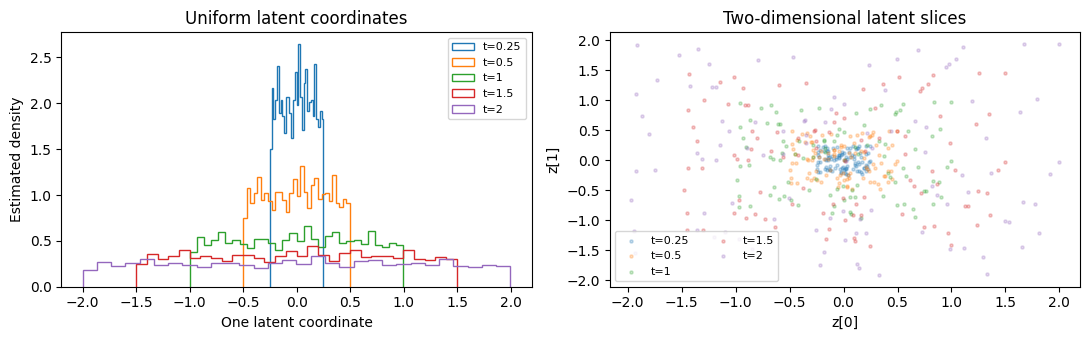

t=0.25: empirical var=0.0208; theoretical var=0.0208
t=0.5: empirical var=0.0833; theoretical var=0.0833
t=1: empirical var=0.3333; theoretical var=0.3333
t=1.5: empirical var=0.7499; theoretical var=0.7500
t=2: empirical var=1.3331; theoretical var=1.3333


In [2]:
def sample_latent(n, threshold=1.0, seed=SEED):
    if threshold <= 0: raise ValueError('Half-range must be positive')
    return np.random.default_rng(seed).uniform(-threshold, threshold, (n, LATENT_DIM)).astype('float32')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for t in TRUNCATION_LEVELS:
    z = sample_latent(2000, t)
    axs[0].hist(z[:, 0], bins=30, density=True, histtype='step', label=f't={t:g}')
    axs[1].scatter(z[:100, 0], z[:100, 1], s=5, alpha=0.25, label=f't={t:g}')
axs[0].set(xlabel='One latent coordinate', ylabel='Estimated density', title='Uniform latent coordinates')
axs[1].set(xlabel='z[0]', ylabel='z[1]', title='Two-dimensional latent slices')
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
for t in TRUNCATION_LEVELS:
    z=sample_latent(5000,t)
    print(f't={t:g}: empirical var={z.var():.4f}; theoretical var={t*t/3:.4f}')

## 3. Prediction exercise — answer *before* seeing results

Write a brief prediction, then compare it with §5:

1. When \(t\) decreases from 1 to 0.25, what happens to latent-coordinate variance?
2. Would you expect **generative precision** (fidelity proxy) to rise, fall, or be uncertain? Why?
3. Would you expect **generative recall** (coverage proxy) to rise, fall, or be uncertain? Why?
4. Which assumption makes it dangerous to attribute all the differences in NB2 to *inference-time* truncation alone?

**Hint:** The generator is nonlinear; the separately trained models do **not** have identical weights.

## 4. Image lab — actual generators trained in NB1/NB2

We now load the **15 original-run generators** (five latent ranges, three training seeds) rather than using random untrained networks. Rows are comparable: 32 samples per condition, with the same NumPy random seed for the input draws. **Note** that the model weights differ between rows, so this is the group's *trained-condition comparison*, not a fixed-model intervention.

**Observation exercise:** At which range are digits easiest to recognise? Which rows show repeated strokes or uncertain shapes? Can you infer true 0–9 digit-class coverage by eye from just 32 images?

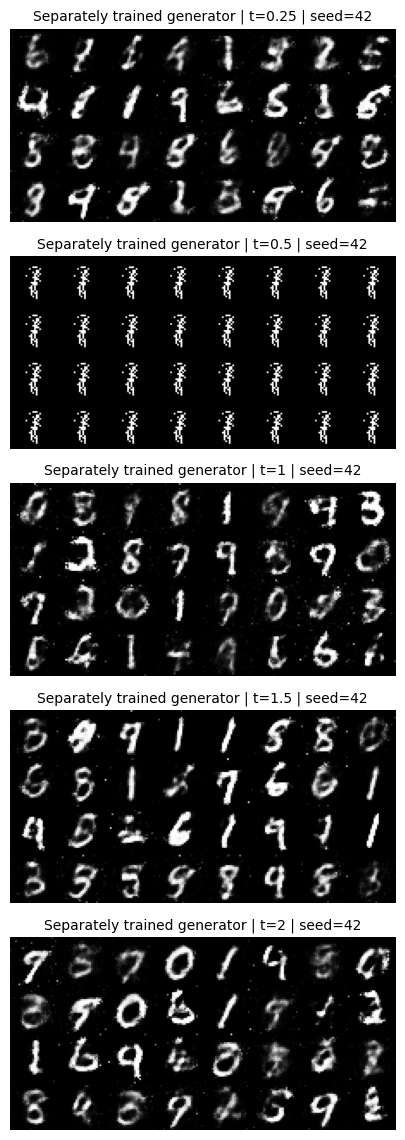

In [3]:
def load_generator(t=1.0, seed=SEED, sensitivity=False):
    return ev.load_generator(RESULTS_DIR,t,seed,lr_variant=sensitivity)

def generate_images(model,t=1.0,n=N_IMAGE_SAMPLES,seed=SEED):
    model.eval()
    with torch.no_grad():
        z=torch.from_numpy(sample_latent(n,t,seed))
        y=model(z).reshape(n,28,28)
    return ((y+1)/2).clamp(0,1).cpu().numpy()

def grid_on_ax(images,ax,title,rows=4,cols=8):
    canvas=np.zeros((rows*28,cols*28),dtype='float32')
    for i,img in enumerate(images[:rows*cols]):
        r,c=divmod(i,cols)
        canvas[r*28:(r+1)*28,c*28:(c+1)*28]=img
    ax.imshow(canvas,cmap='gray',vmin=0,vmax=1)
    ax.set_title(title,fontsize=10);ax.axis('off')

fig,axes=plt.subplots(len(TRUNCATION_LEVELS),1,figsize=(11,11.5))
for ax,t in zip(axes,TRUNCATION_LEVELS):
    grid_on_ax(generate_images(load_generator(t),t),ax,f'Separately trained generator | t={t:g} | seed={SEED}')
plt.tight_layout();plt.show()

### 4.1 A controlled contrast: hold the generator weights fixed

For a **counterfactual illustration**, choose the **NB1 baseline generator** trained at \(t=1\), seed 42. Reuse its **same weights** in every row; vary only the inference-time sampling range. Now the images illustrate a narrower intervention. You will see a numerical version of this comparison in §5.3, using **all three baseline seeds**.

**Notice:** Applying \(t=2\) to a generator trained only on \([-1,1]\) is extrapolation beyond its training input range. Increased variety under this shift may also increase implausible outputs.

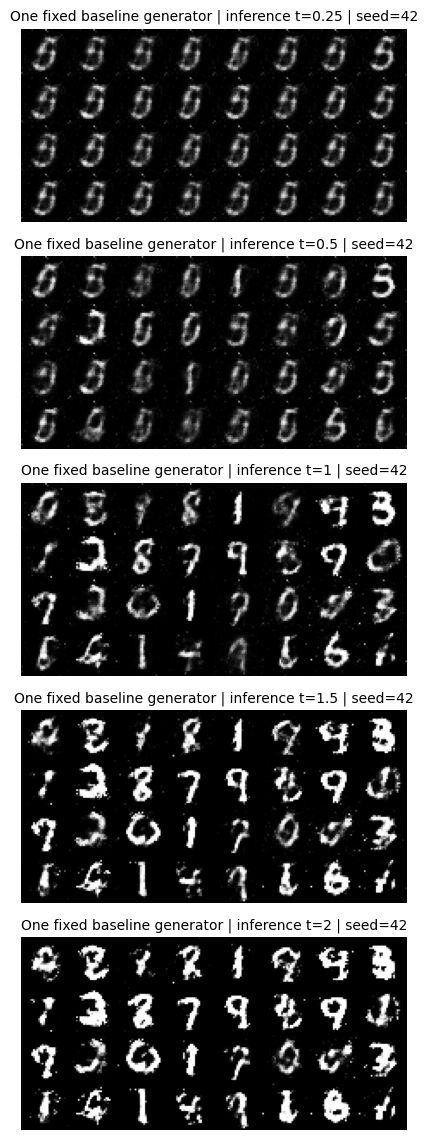

In [4]:
fixed_G=load_generator(1.0,42)
fig,axes=plt.subplots(len(TRUNCATION_LEVELS),1,figsize=(11,11.5))
for ax,t in zip(axes,TRUNCATION_LEVELS):
    grid_on_ax(generate_images(fixed_G,t),ax,f'One fixed baseline generator | inference t={t:g} | seed=42')
plt.tight_layout();plt.show()

## 5. Reading the evidence — generative precision and recall

Our **independent MNIST CNN** maps images to 128-dimensional features. The NB2 metric uses **k=5 neighbourhoods** in feature space:

- **Generative precision:** proportion of generated samples near the real-image feature manifold, a *fidelity proxy*.
- **Generative recall:** proportion of real samples covered by neighbourhoods around generated samples, a *coverage proxy*.

These are **not digit-classification precision/recall**, not human perceptual scores, and not direct measurements of the count of digit classes covered. The neighbourhood definitions, CNN representation and finite sample size affect the values.

**Measurement design:** 2000 real MNIST test images and 2000 generated images per condition; reference real features from the same test segment; a fixed torch noise seed 999; three training seeds. See `nb3_evaluation.py` and original NB2 §6.3–6.5 for the runnable evaluation implementation.

In [5]:
if not QUICK:
    print('Full NB3 analysis: recomputing main, sensitivity and fixed-generator results...')
    start=time.perf_counter()
    ev.recompute_all(RESULTS_DIR,DATA_DIR,CACHE_DIR,num_samples=2000)
    print(f'Full NB3 analysis completed in {time.perf_counter()-start:.1f}s.')
else:
    print('QUICK=True: reading verified metric caches produced from the original checkpoints.')


def read_rows(filename):
    path=CACHE_DIR/filename
    if not path.is_file(): raise FileNotFoundError(f'Missing {path}. Use supplied cache or QUICK=False to regenerate.')
    with path.open(newline='',encoding='utf-8') as f:
        rows=list(csv.DictReader(f))
    for r in rows:
        r['truncation']=float(r['truncation']);r['seed']=int(r['seed'])
        r['precision']=float(r['precision']);r['recall']=float(r['recall'])
    assert len(rows)==15, f'{filename} should contain 5 ranges × 3 seeds, found {len(rows)}'
    return rows

main_rows=read_rows('nb2_main_seed_results.csv')
sensitivity_rows=read_rows('nb2_sensitivity_seed_results.csv')
fixed_rows=read_rows('nb3_fixed_generator_results.csv')

QUICK=True: reading verified metric caches produced from the original checkpoints.


### 5.1 Original experiment: three seeds, five training conditions

The following chart places **all 15 measured points** on each plot rather than hiding large seed-to-seed differences behind an average. The thick points and bars show **mean ± sample standard deviation (n=3)**. The lines joining seed observations are visual aids, **not** a continuous optimisation curve.

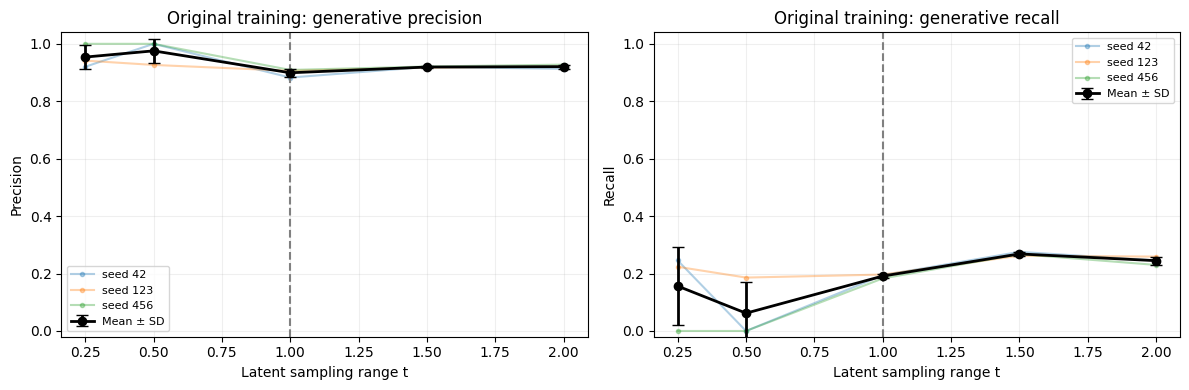

  t  | Precision mean ± SD  | Recall mean ± SD
0.25 | 0.9538 ± 0.0414 | 0.1563 ± 0.1358
 0.5 | 0.9755 ± 0.0424 | 0.0620 ± 0.1074
   1 | 0.8992 ± 0.0145 | 0.1912 ± 0.0072
 1.5 | 0.9192 ± 0.0020 | 0.2683 ± 0.0068
   2 | 0.9205 ± 0.0073 | 0.2448 ± 0.0145


In [6]:
def summarise(rows):
    return {t:{m:(float(np.mean([r[m] for r in rows if r['truncation']==t])),float(np.std([r[m] for r in rows if r['truncation']==t],ddof=1))) for m in ('precision','recall')} for t in TRUNCATION_LEVELS}

def plot_metric(rows,metric,ax,title):
    for seed in RANDOM_SEEDS:
        rr=sorted([r for r in rows if r['seed']==seed],key=lambda r:r['truncation'])
        ax.plot([r['truncation'] for r in rr],[r[metric] for r in rr],alpha=.35,marker='.',label=f'seed {seed}')
    ss=summarise(rows)
    ax.errorbar(TRUNCATION_LEVELS,[ss[t][metric][0] for t in TRUNCATION_LEVELS],
                yerr=[ss[t][metric][1] for t in TRUNCATION_LEVELS],
                color='black',marker='o',capsize=4,linewidth=2,label='Mean ± SD')
    ax.axvline(1,linestyle='--',color='gray')
    ax.set(xlabel='Latent sampling range t',ylabel=metric.capitalize(),title=title,ylim=(-0.02,1.04))
    ax.legend(fontsize=8);ax.grid(alpha=.2)

fig,axes=plt.subplots(1,2,figsize=(12,4))
plot_metric(main_rows,'precision',axes[0],'Original training: generative precision')
plot_metric(main_rows,'recall',axes[1],'Original training: generative recall')
plt.tight_layout();plt.show()
print('  t  | Precision mean ± SD  | Recall mean ± SD')
for t,v in summarise(main_rows).items():
    print(f"{t:>4g} | {v['precision'][0]:.4f} ± {v['precision'][1]:.4f} | {v['recall'][0]:.4f} ± {v['recall'][1]:.4f}")

**Interpretation:** At \(t=0.5\), original-run mean precision is **0.9755** while mean recall is **0.0620**: unusually high feature fidelity coexists with very weak coverage. Two of its three seeds have **zero** recall, so the mean is not a stable stand-alone description. At \(t=1.5\), both precision (**0.9192**) and recall (**0.2683**) exceed the corresponding \(t=1\) baseline means (**0.8992**, **0.1912**) at the original learning rate.

**Student question:** How would your conclusion change if only seed 42 were shown? Identify one result with particularly large seed variance and explain why it matters.

### 5.2 Sensitivity check: change only the learning rate

NB2 includes a lower learning-rate experiment (from **0.002** to **0.0002**), with the **same five sampling ranges and three seeds**. We recomputed this cache from the separate sensitivity checkpoints, using the **same feature metrics**. Comparing these groups tests whether claims are robust to optimisation settings, **not** whether the sampling range alone caused the effect.

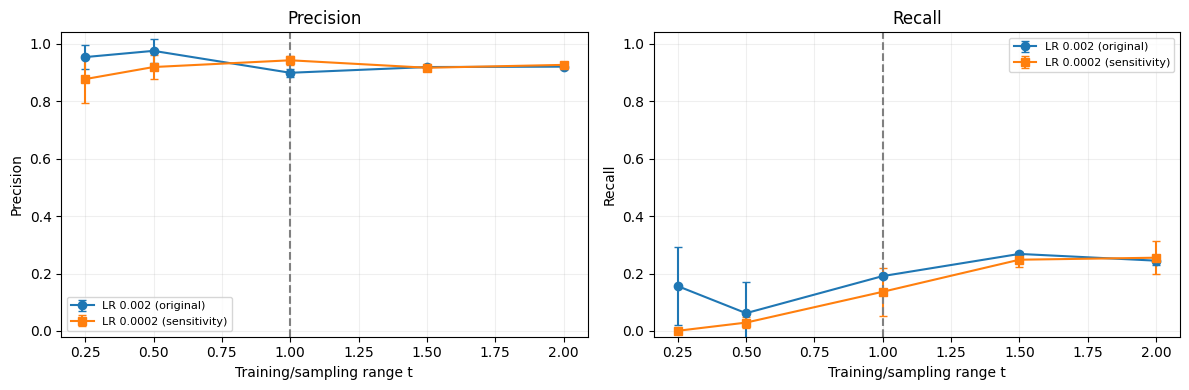

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,('precision','recall')):
    s0=summarise(main_rows);s1=summarise(sensitivity_rows)
    ax.errorbar(TRUNCATION_LEVELS,[s0[t][metric][0] for t in TRUNCATION_LEVELS],yerr=[s0[t][metric][1] for t in TRUNCATION_LEVELS],marker='o',capsize=3,label='LR 0.002 (original)')
    ax.errorbar(TRUNCATION_LEVELS,[s1[t][metric][0] for t in TRUNCATION_LEVELS],yerr=[s1[t][metric][1] for t in TRUNCATION_LEVELS],marker='s',capsize=3,label='LR 0.0002 (sensitivity)')
    ax.axvline(1,color='gray',linestyle='--');ax.set(title=metric.capitalize(),xlabel='Training/sampling range t',ylabel=metric.capitalize(),ylim=(-0.02,1.04))
    ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();plt.show()

**Reading the sensitivity check:** At the lower learning rate, \(t=1.5\) still exceeds \(t=1\) in recall, but its precision is **lower** than the baseline. Thus “\(t=1.5\) improves both metrics” is **not** robust across these two learning rates. This is stronger evidence for a *conditional* conclusion, not a universal optimum.

### 5.3 Fixed-generator analysis: distinguish two explanations

We now quantify §4.1's counterfactual using **the same classifier, 2000-image sample size, k=5, and random noise protocol** as NB2. For each of the **three** baseline generator seeds, we keep the learned weights fixed at the \(t=1\) model and vary **only inference-time** \(t\). This produces 15 separate measured rows cached as `nb3_fixed_generator_results.csv`.

- **Explanation A:** The pattern follows *inference-time* changes to the input distribution.
- **Explanation B:** The pattern arises in part because the GAN **trained under a different input distribution**.

**Caution:** These experiments differ in more than one factor; differences between curves support these explanations as plausible contributors, but they do not quantitatively isolate all interactions or establish universally causal effects.

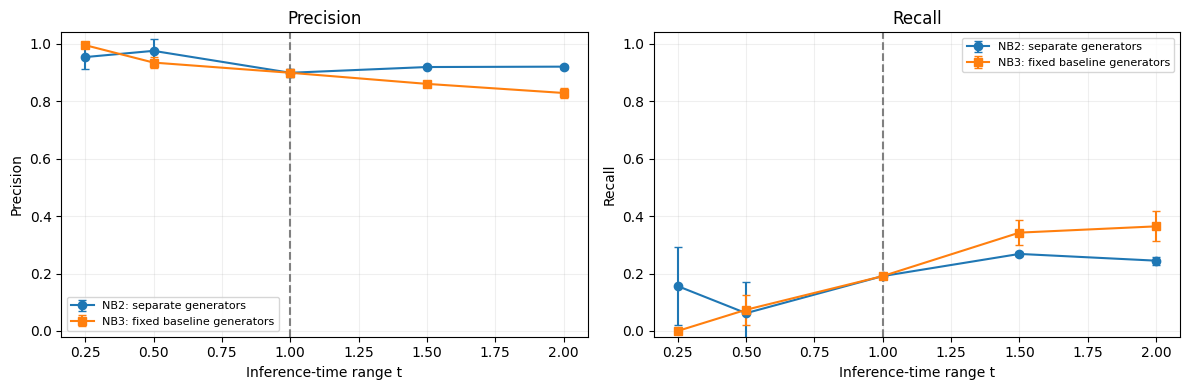

  t  | NB2 separate: P / R | NB3 fixed: P / R (means)
0.25 | 0.9538 / 0.1563 | 0.9953 / 0.0000
 0.5 | 0.9755 / 0.0620 | 0.9347 / 0.0738
   1 | 0.8992 / 0.1912 | 0.8992 / 0.1912
 1.5 | 0.9192 / 0.2683 | 0.8605 / 0.3425
   2 | 0.9205 / 0.2448 | 0.8288 / 0.3643


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sm=summarise(main_rows);sf=summarise(fixed_rows)
for ax,metric in zip(axes,('precision','recall')):
    ax.errorbar(TRUNCATION_LEVELS,[sm[t][metric][0] for t in TRUNCATION_LEVELS],yerr=[sm[t][metric][1] for t in TRUNCATION_LEVELS],marker='o',capsize=3,label='NB2: separate generators')
    ax.errorbar(TRUNCATION_LEVELS,[sf[t][metric][0] for t in TRUNCATION_LEVELS],yerr=[sf[t][metric][1] for t in TRUNCATION_LEVELS],marker='s',capsize=3,label='NB3: fixed baseline generators')
    ax.axvline(1,color='gray',linestyle='--');ax.set(title=metric.capitalize(),xlabel='Inference-time range t',ylabel=metric.capitalize(),ylim=(-0.02,1.04))
    ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.tight_layout();plt.show()
print('  t  | NB2 separate: P / R | NB3 fixed: P / R (means)')
for t in TRUNCATION_LEVELS:
    print(f"{t:>4g} | {sm[t]['precision'][0]:.4f} / {sm[t]['recall'][0]:.4f} | {sf[t]['precision'][0]:.4f} / {sf[t]['recall'][0]:.4f}")

**What the new comparison reveals:** With a **fixed baseline generator**, the mean generative precision generally **falls** as the inference range increases (approximately **0.995** at \(t=0.25\) to **0.829** at \(t=2\)), while recall rises (from **0** to approximately **0.364**). In the separately trained NB2 generators, this pattern is not monotone: the learned mapping itself changes across training conditions. This is direct empirical evidence that **training-time distribution changes are a plausible alternative influence** on the observed NB2 results.

**Important limitation:** The fixed-model extension involves **three baseline seeds**, but no confidence intervals beyond their sample SD; at \(t>1\) it probes out-of-training-range inputs. Do not generalise these MNIST results to other datasets without testing.

**Checkpoint question:** Why is the fixed-generator curve a *better* test of the inference-time truncation claim than the separate-generator curve? What does it still fail to test?

### 5.4 Three Main Findings from NB2


**Finding 1: Image Quality and Diversity**

Visual comparisons show that smaller truncation values, particularly 0.25 and 0.5, sometimes generate repetitive patterns, while 1.5 and 2.0 generally produce more varied and recognisable digits.

**Finding 2: Precision and Recall Across Random Seeds**

At truncation 0.5, the GAN achieves the highest mean generative precision (0.9755), but the lowest mean recall (0.0620). In contrast, truncation 1.5 achieves the highest mean recall (0.2683), while also improving precision compared with the baseline under the original learning rate.

**Finding 3: Mode Collapse**

Some runs at smaller truncation values repeatedly generate very similar images. In particular, two seeds at truncation 0.5 achieve zero recall, which is consistent with mode collapse. This demonstrates why high generative precision alone does not guarantee diversity.

**Overall Conclusion**

These findings partially support our research hypothesis. Narrower latent sampling ranges can reduce sample diversity, but they do not consistently improve image quality. Because the original experiments used separately trained generators, the findings also cannot be attributed solely to inference-time truncation.

## 6. Alternative explanations, limitations and what we can claim

1. **Confounded intervention in NB2.** Altering the noise range during **training and sampling** changes the generator weights, so NB2 does not isolate post-training truncation.
2. **Sensitivity to optimisation.** The learning-rate check changes whether \(t=1.5\) improves precision relative to baseline. Hyperparameter tuning and training instability remain possible explanations.
3. **Small samples of stochastic training.** Only three random seeds per condition; some conditions show pronounced seed-level instability. Means without their spread can mislead.
4. **Proxy metrics.** Neighbourhood precision and recall depend on the CNN feature representation and k=5. High precision is not a human judg(e)ment that every digit is legible; recall is not an explicit count of all ten digit classes.
5. **Dataset and architecture.** Results are specific to MNIST, fully connected GANs, and the settings saved in the checkpoints. Inference-time \(t>1\) also explores outside the baseline latent training support.

### Answer to our research question

**Partially supported, with an important qualification.** Narrow ranges can produce higher generative precision with much lower coverage, but improvements are not universal across all ranges, seeds and learning rates. The separately trained experiment alone cannot establish the standard inference-only truncation claim. The fixed-model comparison offers clearer evidence of a precision/recall trade-off under inference-only changes while revealing a different pattern from separately trained models.

## 7. Apply what you learned — two short exercises

**Exercise A: Predict → observe → explain (3 minutes).**

- Return to §3. Which prediction about the *input variance* was guaranteed, and which about image quality was uncertain?
- Why does the original \(t=0.5\) condition not justify claiming “the GAN is best” despite its high mean precision?
- Why is the three-seed spread important, particularly when two seeds collapse in recall?

**Exercise B: Choose a GAN for an application (2 minutes).**

- You need a few close-to-real handwriting samples for a small illustration. Which results would you inspect first?
- You instead need a wide variety of handwriting styles for training a downstream model. Would you optimise precision or recall? Why is predicted digit-class coverage still worth checking separately?
- Would you claim the “optimal \(t\)” transfers to faces, art or medical images? Explain your boundary of inference.

<details><summary>Suggested discussion guidance — attempt first</summary>

- Variance equals \(t^2/3\) by definition; pixel-level clarity depends on nonlinear learned weights.
- Precision near 1 can coexist with severe loss of real-distribution coverage, or even repeated near-identical patterns. Seed variation shows the risk of cherry-picking a good run.
- For fidelity-heavy applications, inspect precision *and actual images*; for diversity-heavy applications inspect recall, class coverage and within-class variation. Neither metric alone gives a complete answer.
- No: the evidence comes from one dataset, architecture, feature model and limited training seeds.
</details>

## 8. Reproduction responsibilities and mode semantics

- `QUICK=True` loads **all three reproducible CSV caches** and uses the submitted checkpoints for the image labs. This is the intended **under-five-minute teaching route**.
- `QUICK=False` runs **all of NB3's quantitative evaluations again** (main 15 + sensitivity 15 + fixed 15 = 45 measured rows). It regenerates the displayed CSVs from the checkpoint weights, CNN feature extractor, MNIST test data and NB2's k=5 neighbourhood definition.
- **GAN retraining** is performed by **NB1 (baseline)** and **NB2 (five conditions + sensitivity)** using their own `QUICK=False`; those notebooks contain the original 100-epoch training code and save the exact checkpoint format used by NB3. NB3 does not misleadingly advertise a 12-step toy GAN as complete GAN retraining.

The source files `NB1.ipynb`, `NB2.ipynb` and `nb3_evaluation.py` accompany this notebook. A marker should be able to review the group's full experiment code without requiring the slow training run. To re-create the raw checkpoint **weights**, run the appropriate NB1/NB2 full-training notebook first; to re-create the **evaluation caches** from the supplied weights, set NB3 `QUICK=False`.

In [9]:
# Fast-mode / provenance validation: each CSV is a complete 5x3 grid.
for name,rows in [('original',main_rows),('sensitivity',sensitivity_rows),('fixed',fixed_rows)]:
    assert {(r['truncation'],r['seed']) for r in rows} == {(t,s) for t in TRUNCATION_LEVELS for s in RANDOM_SEEDS}
    assert all(0<=r['precision']<=1 and 0<=r['recall']<=1 for r in rows)
    print(f'{name}: 15 results checked')
assert np.allclose([summarise(main_rows)[t]['precision'][0] for t in TRUNCATION_LEVELS],
                   [0.9538333333,0.9755,0.8991666667,0.9191666667,0.9205],atol=0.0001)
print('Original-run means match NB2 Section 8.2 to the reported rounding.')

original: 15 results checked
sensitivity: 15 results checked
fixed: 15 results checked
Original-run means match NB2 Section 8.2 to the reported rounding.


## 9. Key takeaways, sources and traceability

1. Reducing the half-range \(t\) necessarily reduces **latent-coordinate variance**, but does not necessarily raise **perceptual quality**.
2. In NB2's original experiments, narrow ranges sometimes gave high **generative precision** and low **recall**; the purported precision advantage of \(t=1.5\) did **not** survive the learning-rate sensitivity check.
3. **Fixed-generator inference tests** reveal a clearer precision–recall trade-off, but only for the tested baseline architecture and MNIST feature metric.
4. The strongest interpretation is **conditional**: changing the latent distribution can alter both fidelity and coverage, while training-time choices and evaluation design also matter.

**Sources and attribution:** (i) Simon J. D. Prince, *Understanding Deep Learning*, Chapter 15, §15.3 (truncation trick); (ii) this group's `NB1.ipynb`, `NB2.ipynb`, all provided checkpoints and `results/mnist_classifier.pt`; (iii) `nb3_evaluation.py` faithfully implements the group's feature-space neighbourhood evaluation for the supplemental controlled analysis. The main, sensitivity and fixed-generator CSVs in `nb3_cache/` are derived results, not manually invented or interchangeable experiments.

**For the presentation:** Distinguish “we trained different GANs” from “we held the GAN fixed”; do not call generative precision an objective visual-quality score.